# Problem 1 — RNN, LSTM and GRU
Run from the project root. Set the runtime to GPU in Colab when available. The full experiment suite can take several hours; reduce epochs only if necessary and report the change.

In [1]:
import os, sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
from config import *
from problem1.core import *
import pandas as pd
print("Device:", get_device(), "h:", HIDDEN_SIZE, "seeds:", SEEDS)

Device: cpu h: 32 seeds: [42, 123, 2026]


## Task 1 — Data pipelines and generator tests

Adding generator tests passed
(5952, 128, 9) (1400, 128, 9) (2947, 128, 9) held-out subjects: [16  3 22 23]


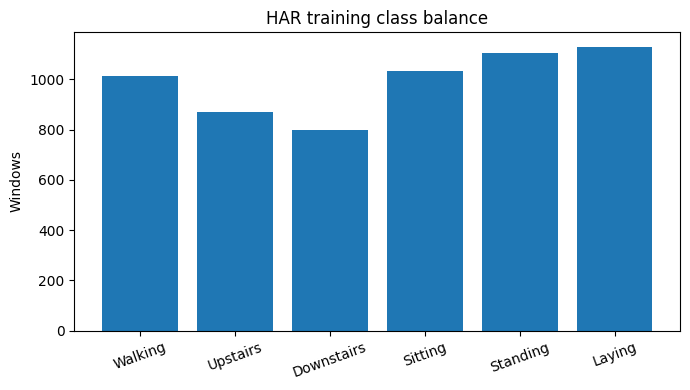

In [2]:
test_adding_generator()
print("Adding generator tests passed")
(x,y),(xv,yv),(xt,yt),ytr,val_subjects = load_har(SEEDS[0])
print(x.shape, xv.shape, xt.shape, "held-out subjects:", val_subjects)
plot_class_balance(ytr, FIG1/"class_balance.png")

## Task 2 — From-scratch cells and PyTorch verification

In [3]:
print("Maximum absolute errors:", verify_cells())
print("Single-bias theoretical counts at d=9, h=32:", scratch_parameter_counts())
for kind in ["RNN","LSTM","GRU"]:
    ref={"RNN":nn.RNN,"LSTM":nn.LSTM,"GRU":nn.GRU}[kind](9,HIDDEN_SIZE)
    print(kind, "PyTorch count incl. two biases:", sum(p.numel() for p in ref.parameters()))

Maximum absolute errors: {'RNN': 8.940696716308594e-08, 'LSTM': 1.1920928955078125e-07, 'GRU': 1.7881393432617188e-07}
Single-bias theoretical counts at d=9, h=32: {'RNN': 1344, 'LSTM': 5376, 'GRU': 4032}
RNN PyTorch count incl. two biases: 1376
LSTM PyTorch count incl. two biases: 5504
GRU PyTorch count incl. two biases: 4128


## Task 3 — HAR classification (3 seeds × 3 models)

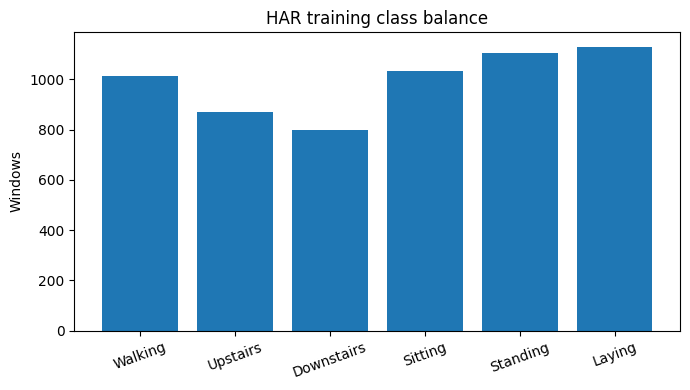

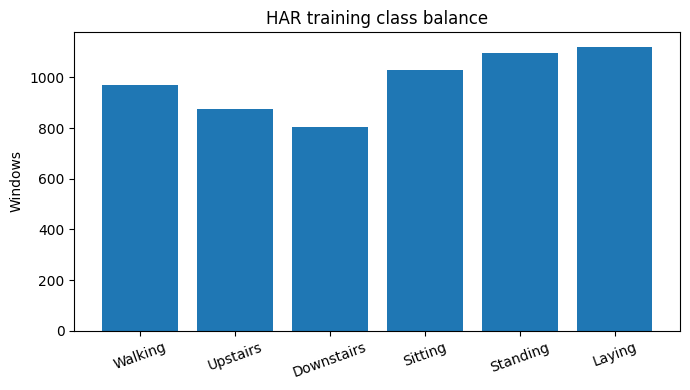

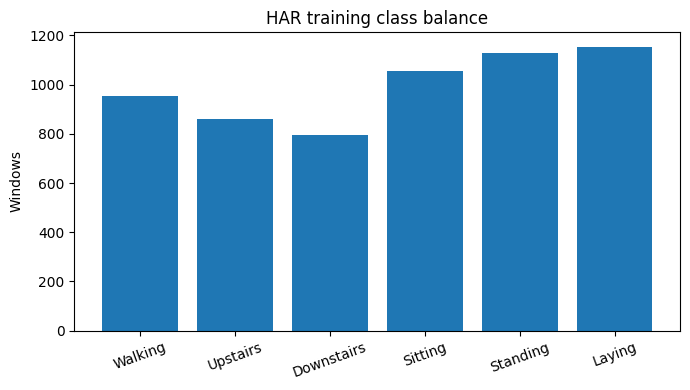

,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
0,P1-HAR,RNN,42,128,0.556837,0.508952,,1574,2.670156,,,epochs=12; validation subjects held out
1,P1-HAR,LSTM,42,128,0.819138,0.817239,,5702,1.564258,,,epochs=12; validation subjects held out
2,P1-HAR,GRU,42,128,0.880896,0.880752,,4326,6.545406,,,epochs=12; validation subjects held out
3,P1-HAR,RNN,123,128,0.684425,0.676066,,1574,2.478762,,,epochs=12; validation subjects held out
4,P1-HAR,LSTM,123,128,0.877503,0.876466,,5702,1.887935,,,epochs=12; validation subjects held out
5,P1-HAR,GRU,123,128,0.872752,0.873903,,4326,6.614283,,,epochs=12; validation subjects held out
6,P1-HAR,RNN,2026,128,0.664065,0.642200,,1574,2.588057,,,epochs=12; validation subjects held out
7,P1-HAR,LSTM,2026,128,0.806583,0.805722,,5702,0.962125,,,epochs=12; validation subjects held out
8,P1-HAR,GRU,2026,128,0.902952,0.903607,,4326,2.920300,,,epochs=12; validation subjects held out


HAR mean ± sample std by model:


test_acc            macro_f1            params      sec_per_epoch  \
           mean       std      mean       std    mean  std          mean   
model                                                                      
GRU    0.885533  0.015625  0.886087  0.015554  4326.0  0.0      5.359997   
LSTM   0.834408  0.037845  0.833142  0.037959  5702.0  0.0      1.471440   
RNN    0.635109  0.068545  0.609073  0.088345  1574.0  0.0      2.578992   

                 
            std  
model            
GRU    2.113120  
LSTM   0.469832  
RNN    0.096019

In [4]:










har_results = run_har()
display(har_results)
print("HAR mean ± sample std by model:")
display(har_results.groupby("model")[["test_acc","macro_f1","params","sec_per_epoch"]].agg(["mean","std"]))

## Task 4 — Adding problem, four lengths and three seeds

In [5]:
adding_results = run_adding()
display(adding_results.groupby(["model","seq_len"]).test_mse.agg(["mean","std"]))
display(pd.read_csv(ROOT/"problem1"/"adding_solved.csv"))

mean       std
model seq_len                    
GRU   50       0.025418  0.016532
      100      0.159457  0.005912
      200      0.166901  0.000763
      400      0.153115  0.000390
LSTM  50       0.175179  0.001949
      100      0.170863  0.001386
      200      0.168967  0.000847
      400      0.153153  0.000173
RNN   50       0.174548  0.000615
      100      0.169676  0.000140
      200      0.167652  0.000095
      400      0.152959  0.000142

,model,seq_len,solved
0,GRU,50,3
1,GRU,100,0
2,GRU,200,0
3,GRU,400,0
4,LSTM,50,0
5,LSTM,100,0
6,LSTM,200,0
7,LSTM,400,0
8,RNN,50,0
9,RNN,100,0


## Task 5 — Gradient analysis, hidden-size sweep and ablation

In [6]:
run_gradient_plots()
hidden_results = run_hidden_sweep()
ablation_results = run_ablation()
display(hidden_results); display(ablation_results)

,seed,hidden_size,model,test_acc,macro_f1,params,sec_per_epoch
0,42,16,LSTM,0.750933,0.740747,1830,0.578234
1,42,16,GRU,0.815066,0.813279,1398,2.345980
2,42,32,LSTM,0.819138,0.817239,5702,0.790750
3,42,32,GRU,0.880896,0.880752,4326,2.851057
4,42,64,LSTM,0.840176,0.840115,19590,1.553945
5,42,64,GRU,0.883610,0.883001,14790,4.653353
6,42,128,LSTM,0.783509,0.776632,71942,4.071003
7,42,128,GRU,0.903970,0.903747,54150,7.746102
8,123,16,LSTM,0.726841,0.712846,1830,1.246443
9,123,16,GRU,0.861215,0.861588,1398,3.048291


,seed,forget_bias,test_mse,sec_per_epoch
0,42,0.0,0.168165,2.128407
1,42,1.0,0.168081,1.922559
2,123,0.0,0.169043,2.115115
3,123,1.0,0.168848,2.307107
4,2026,0.0,0.169831,2.028086
5,2026,1.0,0.169732,1.931681
